# Superstore Sales Analysis: Exploratory Data Analysis (EDA)

**Goal:** explore the cleaned data to find where sales come from and how they change over time, by product, region, customer and shipping method.

**Input:** **Input:** `data/processed/superstore_clean.csv` (output of notebook 01)

**Note:** this dataset has no Profit, Quantity or Discount columns, so all findings are based on `Sales`.

Each section has a short explanation, the code, and a **Finding** line that feeds the final insights and recommendations.

## Setup

Load the libraries and the **cleaned** file (not the raw one). `parse_dates` keeps the date columns as datetimes.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("../data/processed/superstore_clean.csv", parse_dates=["Order Date", "Ship Date"])

## 1. Headline KPIs

Totals that summarize the business: total sales, number of orders, number of customers, average order value and the period covered. Orders are counted with `nunique()` on `Order ID` because one order can span several rows, and the average order value sums sales per order first.

In [2]:
print("Total sales:", round(df["Sales"].sum(), 2))
print("Orders:", df["Order ID"].nunique())
print("Customers:", df["Customer ID"].nunique())
print("Avg order value:", round(df.groupby("Order ID")["Sales"].sum().mean(), 2))
print("Date range:", df["Order Date"].min().date(), "→", df["Order Date"].max().date())

Total sales: 2261255.41
Orders: 4922
Customers: 793
Avg order value: 459.42
Date range: 2015-01-03 → 2018-12-30


**Finding:** _Total sales were about 2.26M across 4,922 orders from 793 customers (2015-01-03 to 2018-12-30). The average order value is 459, roughly 2 product lines per order, which is why the average order is much higher than the median single line (about 54)._

## 2. Sales over time

Yearly totals and growth percentage show the overall trend. The monthly line chart (one line per year) shows **seasonality**: which months are consistently high or low.

Year
2015    479574.8361
2016    459436.0054
2017    600192.5500
2018    722052.0192
Name: Sales, dtype: float64 
Growth %:
 Year
2015     NaN
2016    -4.2
2017    30.6
2018    20.3
Name: Sales, dtype: float64


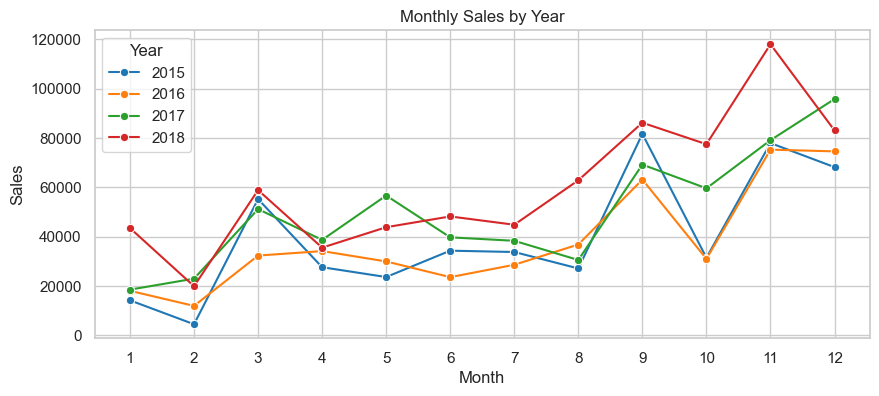

In [3]:
yearly = df.groupby("Year")["Sales"].sum()
print(yearly, "\nGrowth %:\n", yearly.pct_change().mul(100).round(1))

monthly = df.groupby(["Year", "Month"])["Sales"].sum().reset_index()
plt.figure(figsize=(10,4))
sns.lineplot(data=monthly, x="Month", y="Sales", hue="Year", marker="o", palette="tab10")
plt.title("Monthly Sales by Year"); plt.xticks(range(1,13))
plt.savefig("../images/monthly_sales.png", dpi=150, bbox_inches="tight"); plt.show()


**Finding:** _Sales dipped 4.2% in 2016, then grew 30.6% and 20.3%. September to December produce 51.8% of sales, peaking in November; February is the weakest month._

## 3. Category and sub-category

Which product groups generate the most sales? The percentage table shows each category's share of total sales, and the bar chart ranks the 17 sub-categories.

Category
Technology         36.6
Furniture          32.2
Office Supplies    31.2
Name: Sales, dtype: float64


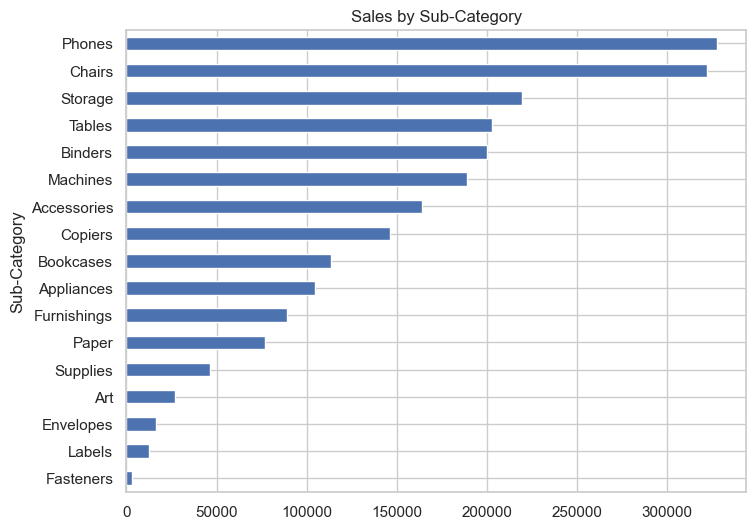

In [4]:
cat = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
sub = df.groupby("Sub-Category")["Sales"].sum().sort_values()

print((cat / cat.sum() * 100).round(1))
sub.plot(kind="barh", figsize=(8,6), title="Sales by Sub-Category")
plt.savefig("../images/sales_by_subcategory.png", dpi=150, bbox_inches="tight"); plt.show()

**Finding:** _The three categories are almost balanced: Technology 36.6%, Furniture 32.2%, Office Supplies 31.2%. Phones and Chairs are the two leading sub-categories (about 320K+ each, roughly 29% of sales together). Fasteners, Labels, Envelopes, Art and Supplies each contribute very little (a few percent in total)._

## 4. Geography and segment

Where do sales come from (region and top 10 states) and which customer segment buys the most (Consumer, Corporate, Home Office)?

In [5]:
print(df.groupby("Region")["Sales"].sum().sort_values(ascending=False))
print(df.groupby("State")["Sales"].sum().sort_values(ascending=False).head(10))
print(df.groupby("Segment")["Sales"].sum())

Region
West       710219.6845
East       669237.3540
Central    492646.9132
South      389151.4590
Name: Sales, dtype: float64
State
California      446306.4635
New York        306361.1470
Texas           168572.5322
Washington      135206.8500
Pennsylvania    116276.6500
Florida          88436.5320
Illinois         79236.5170
Michigan         76136.0740
Ohio             74848.9780
Virginia         70636.7200
Name: Sales, dtype: float64
Segment
Consumer       1.148061e+06
Corporate      6.884941e+05
Home Office    4.247008e+05
Name: Sales, dtype: float64


**Finding:** _West (31%) and East (30%) lead, while South is the weakest (17%). California and New York alone produce about 33% of all sales, and the top 10 states about 69%. Consumers account for 51% of sales, Corporate 30% and Home Office 19%._

## 5. Customers

The top 10 customers by sales, and the share of total sales produced by the top 10% of customers. A high share means revenue depends on a small group of customers (a retention priority).

In [6]:
cust = df.groupby("Customer Name")["Sales"].sum().sort_values(ascending=False)
print(cust.head(10))
print("Top 10% of customers' share of sales:",
      round(cust.head(int(len(cust)*0.1)).sum() / cust.sum() * 100, 1), "%")

Customer Name
Sean Miller           25043.050
Tamara Chand          19052.218
Raymond Buch          15117.339
Tom Ashbrook          14595.620
Adrian Barton         14473.571
Ken Lonsdale          14175.229
Sanjit Chand          14142.334
Hunter Lopez          12873.298
Sanjit Engle          12209.438
Christopher Conant    12129.072
Name: Sales, dtype: float64
Top 10% of customers' share of sales: 30.9 %


**Finding:** _The top 10% of customers (about 79) generate 30.9% of sales (31.2% in the SQL analysis, which puts 80 customers in the first group). Revenue is therefore somewhat concentrated but not dependent on a few accounts: the largest customer (Sean Miller, about 25K) is only about 1.1% of sales. Customers are also loyal: they place about 6 orders each over four years._

## 6. Shipping

Average delivery time and number of lines per ship mode, plus the sales handled by each mode. This shows whether the speed of each mode matches its promise and which mode customers prefer.

In [7]:
print(df.groupby("Ship Mode")["Shipping Days"].agg(["mean", "count"]).round(2))
print(df.groupby("Ship Mode")["Sales"].sum())

                mean  count
Ship Mode                  
First Class     2.18   1501
Same Day        0.04    538
Second Class    3.25   1902
Standard Class  5.01   5858
Ship Mode
First Class       3.455723e+05
Same Day          1.252190e+05
Second Class      4.499142e+05
Standard Class    1.340550e+06
Name: Sales, dtype: float64


**Finding:** _Standard Class is used for about 60% of lines and sales. Average delivery matches each mode’s promise: Same Day 0.04 days, First Class 2.2, Second Class 3.3, Standard Class 5.0._

## 7. Distribution of Sales

Sales are heavily right-skewed (many small purchases, a few very large ones), so the histogram uses a **log scale** to make the shape readable. Large values are kept because they are genuine big purchases, not errors.

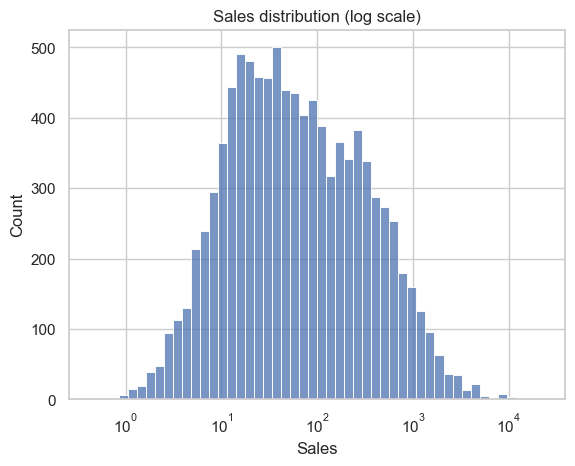

In [8]:
sns.histplot(df["Sales"], bins=50, log_scale=True)
plt.title("Sales distribution (log scale)")
plt.savefig("../images/sales_distribution.png", dpi=150, bbox_inches="tight"); plt.show()

**Finding:** _Most sales fall between about 10 and 1,000, with a peak around 30 to 50. Very large sales (above 10,000) are rare, which explains why the mean is much higher than the median._

## Key insights and recommendations

1. **Growth after a 2016 dip:** Sales fell 4.2% in 2016, then grew 30.6% in 2017 and 20.3% in 2018 (reaching about 722K).
   **Recommendation:** identify what changed in 2017 (new products, regions, customers) and repeat it.

2. **Strong September to December seasonality:** these four months produce 51.8% of annual sales, with the peak in November. January, February and April are the weakest months.
   **Recommendation:** build stock, staffing and promotions ahead of September, and run campaigns in the weak months (especially February).

3. **Product sales are concentrated:** Phones and Chairs make up 28.8% of sales, while the five lowest sub-categories (including Fasteners and Labels) contribute only 4.6%.
   **Recommendation:** protect availability of the top sellers, and review or bundle the lowest-selling items with the top sellers.

4. **Geographic concentration:** California and New York produce about 33% of sales, the top 10 states about 69%, and the South is the weakest region (17%).
   **Recommendation:** defend the top states, and test marketing or partnerships in the South and Central regions.

5. **Customer mix and loyalty:** Consumers generate 51% of sales and the top 10% of customers about 31%. Customers are very loyal: 98.4% ordered more than once (6.2 orders on average).
   **Recommendation:** start a loyalty program for the top customers, and develop the Corporate segment with bulk-order offers.

6. **Shipping preference:** Standard Class handles about 59% of sales.
   **Recommendation:** test a free-shipping threshold or a small premium for faster modes.